# 09b-overcluster-merge — Gộp cụm con về 5 cụm bằng Bayes factor NIW

**Câu hỏi** (B13; E09.06, Q14.04): lợi của `09a` + `09b` ở bước 09 đi qua các bước 10–14 thế nào, lớp cũ mất ở đâu, và cụm con của rolled_pit bị gộp vào đâu?

**Vị trí:** chèn (loại 2), chạy ngay sau `09a-overcluster` trong bước 09; dựa trên `09-cluster` và `09d-ownership`. Notebook này chỉ đọc run đã commit của E09.06 và chạy lại phần phân cụm, không chạy SVI.

In [1]:
# cell 0: provenance (run first)
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "main.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / "lab")]
import replay; os.environ["XLA_FLAGS"] = replay._xla_flags()   # GPU deterministic mode before any jax import
git = lambda *a: subprocess.run(["git", *a], capture_output=True, text=True).stdout.strip()
print("commit", git("rev-parse", "--short", "HEAD"),
      "| code dirty", bool(git("status", "--porcelain", "--", ".", ":(exclude)runs", ":(exclude)notes",
                               ":(exclude)lab/*.ipynb", ":(exclude)lab/*.md")),
      "| XLA_FLAGS", os.environ["XLA_FLAGS"])

commit 5e4b3c8 | code dirty False | XLA_FLAGS --xla_gpu_deterministic_ops=true


- **Kết quả**: commit `5e4b3c8`, code dirty False, XLA_FLAGS `--xla_gpu_deterministic_ops=true`.
- **Ý nghĩa**: dirty phải là False; đạt.

## 1. Kiểm

### 1.1 Bảng quyết định của E09.06
Chạy lại `score.e0906_summary` trên 30 run đã commit. Bảng phải cho đúng quyết định đã ghi ở `b06586c`.

In [2]:
import json
import numpy as np, pandas as pd
from scipy import stats
import score
pd.set_option("display.width", 250)
T, B = 0.0273, 0.615
summ = score.e0906_summary(T, B)

       draws  off  n_parts  D_bal14  s_bal14  D_S1_Old  s_S1_Old  D_bal10  D_stop_S  k0_bal14  k0_S1_Old  purity  silk_owned_bf  t1_def  t1_k20   t1_bf  t1_ward  t1_bhatt  t1_bhatt_mean
snap                                                                                                                                                                                     
r0_s0     21   10       41   0.0061   0.0348   -0.3754    0.7412   0.0549   13.0000    0.0105    -0.8299  0.5079         2.0476  0.5184  0.4109  0.5582   0.5558    0.3046         0.2578
r0_s1     21   10       42   0.0024   0.0597   -0.1581    0.5162   0.0298   12.9524   -0.0631     0.8299  0.5365         2.0476  0.5135  0.3974  0.5499   0.5473    0.2971         0.2668
r0_s2     21   10       40   0.0094   0.0373   -0.1383    0.4968   0.0438    4.7143    0.0262    -0.4149  0.5333         2.0000  0.5398  0.4101  0.5729   0.5402    0.3076         0.2688
r0_s3     21   10       42   0.0069   0.0519    0.0000    0.8899   0.0

- **Kết quả**: quyết định `accept`; Δ = 0.06419, Δ_r = 0.0080 / 0.1122 / 0.0724, Δ_Old = −0.5295 điểm, SE_MC 0.00363 và 0.0425; T, B tính lại 0.02728 và 0.61545. rolled có cụm riêng ở K' = 20 trong 203/315 cặp, giữ được sau gộp ở 0.015 số đó; crease 187 cặp, giữ 0.615. silk sở hữu đúng 1 cụm sau gộp ở 0/315 cặp.
- **Ý nghĩa**: trùng bảng quyết định của E09.06 (`b06586c`). rolled mất cụm ở phép gộp, không ở sức chứa K' = 20; mục 5 xem nó bị gộp vào đâu.

### 1.2 Bảng dài: mỗi dòng một cặp (ảnh chụp, lần rút)
Đọc thẳng `metrics.json`, mỗi cặp có hai nhánh: `def` (k-means K = 5) và `var` (`09a` + `09b`). Cột `d_*` là `var` trừ `def`. Trung bình theo ảnh chụp phải trùng bảng 1.1.

In [3]:
NOV = ["silk", "inclusion", "rolled", "crease", "waist"]
split = json.load(open(ROOT / "splits/gc10_split.json"))
N_TEST = {c.split("_")[0]: len(split["test"][c]) for c in split["classes"][split["n_base"]:]}   # novel test images
N_OLD_TEST = sum(len(split["test"][c]) for c in split["classes"][:split["n_base"]])
files = sorted((ROOT / "runs").glob("*__gc10_e09_06*_r*_s*/metrics.json"))
print(len(files), "runs:", files[0].parent.name, "...", files[-1].parent.name, "| novel test", N_TEST, "| old test", N_OLD_TEST)
rows, RAW = [], {}
for f in files:
    m = json.loads(f.read_text())
    assert m["checks_ok"] == 1, f
    for k in range(m["k_first"], m["k_last"] + 1):
        RAW[(m["ft_seed"], m["seed"], k)] = m
        row = dict(ft=f"r{m['ft_seed']}", seed=m["seed"], draw=k, snap=f"r{m['ft_seed']}_s{m['seed']}", batch=m["k_first"])
        for arm, t1 in (("def", "def"), ("var", "bf")):
            g = lambda key: m[f"d{k}_{arm}_{key}"]
            row.update({f"{arm}_t1": m[f"d{k}_t1_{t1}_bal"], f"{arm}_bal10": g("bal10"), f"{arm}_bal14": g("bal14"),
                        f"{arm}_old14": g("old14"), f"{arm}_kept": g("kept"), f"{arm}_stop_S": g("stop_S"),
                        f"{arm}_S1_Old": g("S1_Old"), f"{arm}_part": g("part")})
            row.update({f"{arm}_rec14_{c}": g(f"right14_{c}") / N_TEST[c] for c in NOV})
            row.update({f"{arm}_{q}_{c}": m[f"d{k}_t1_{t1}_{q}_{c}"] for c in NOV for q in ("best", "owned")})
        assert m[f"d{k}_var_old08"] == m[f"d{k}_def_old08"]
        row["old08"] = m[f"d{k}_def_old08"]
        rows.append(row)
L = pd.DataFrame(rows).sort_values(["ft", "seed", "draw"]).reset_index(drop=True)
for key in ("t1", "bal10", "bal14", "old14", "kept", "stop_S", "S1_Old"):
    L[f"d_{key}"] = L[f"var_{key}"] - L[f"def_{key}"]
print(len(L), "pairs;", L.groupby("ft").size().to_dict(), "| draws per snapshot", sorted(L.groupby("snap").size().unique().tolist()))
by_snap = L.groupby(["ft", "snap"])[["d_bal14", "d_S1_Old", "d_bal10", "d_stop_S"]].mean()
chk = by_snap.groupby("ft").mean()
print(chk.round(5).to_string())
print("Delta", round(chk["d_bal14"].mean(), 5), "| Delta_Old", round(chk["d_S1_Old"].mean(), 4))
same = np.allclose(by_snap["d_bal14"].to_numpy(), summ["D_bal14"].to_numpy()) and \
       np.allclose(by_snap["d_S1_Old"].to_numpy(), summ["D_S1_Old"].to_numpy())
print("long table reproduces e0906_summary per snapshot:", same)
assert same

30 runs: 20261112_231509__gc10_e09_06_r0_s0 ... 20261113_152145__gc10_e09_06x_r2_s4 | novel test {'silk': 124, 'inclusion': 43, 'rolled': 6, 'crease': 11, 'waist': 30} | old test 241
315 pairs; {'r0': 105, 'r1': 105, 'r2': 105} | draws per snapshot [21]
    d_bal14  d_S1_Old  d_bal10  d_stop_S
ft                                      
r0  0.00796  -0.13831  0.05191  16.20000
r1  0.11221  -0.55325  0.12628  44.71429
r2  0.07239  -0.89706  0.11989  52.62857
Delta 0.06419 | Delta_Old -0.5295
long table reproduces e0906_summary per snapshot: True


- **Kết quả**: 30 run, 315 cặp (105 mỗi FT seed, 21 lần rút mỗi ảnh chụp); test lớp mới 124 / 43 / 6 / 11 / 30 ảnh, test lớp cũ 241. Trung bình theo ảnh chụp của `d_bal14` và `d_S1_Old` trùng `e0906_summary`.
- **Ý nghĩa**: bảng dài dùng được cho mục 3 và 4.

### 1.3 Độ vững ở mức FT seed, và độ mịn của thước
Kết luận về biểu diễn lấy FT seed làm đơn vị (n = 3; `lab/README.vi.md` §9). 

**Cách làm:** khoảng tin cậy 95% của trung bình Δ_r theo phân phối Student-t với n − 1 = 2 bậc tự do (Student 1908): Δ ± t₀.₉₇₅,₂ · SD/√3. Kèm theo: một ảnh test đáng bao nhiêu trên mỗi thước.

In [4]:
d_r = chk["d_bal14"].to_numpy(); n = len(d_r)
tq = stats.t.ppf(0.975, n - 1); se = d_r.std(ddof=1) / np.sqrt(n)
print(f"Delta_r {np.round(d_r, 4).tolist()} mean {d_r.mean():.4f} SD {d_r.std(ddof=1):.4f} SE {se:.4f} "
      f"t {d_r.mean() / se:.2f} (df {n - 1}) 95% CI [{d_r.mean() - tq * se:.4f}, {d_r.mean() + tq * se:.4f}] "
      f"p {2 * stats.t.sf(abs(d_r.mean() / se), n - 1):.3f}")
o_r = chk["d_S1_Old"].to_numpy(); se = o_r.std(ddof=1) / np.sqrt(n)
print(f"Delta_Old_r {np.round(o_r, 3).tolist()} mean {o_r.mean():.3f} 95% CI [{o_r.mean() - tq * se:.3f}, {o_r.mean() + tq * se:.3f}]")
print(f"one old test image = {100 / N_OLD_TEST:.3f} points of S1_Old; B = {B / (100 / N_OLD_TEST):.2f} images")
print("one novel test image in balanced novel:", {c: round(1 / (N_TEST[c] * len(NOV)), 4) for c in NOV}, "| T =", T)

Delta_r [0.008, 0.1122, 0.0724] mean 0.0642 SD 0.0526 SE 0.0304 t 2.11 (df 2) 95% CI [-0.0665, 0.1949] p 0.169
Delta_Old_r [-0.138, -0.553, -0.897] mean -0.530 95% CI [-1.473, 0.414]
one old test image = 0.415 points of S1_Old; B = 1.48 images
one novel test image in balanced novel: {'silk': 0.0016, 'inclusion': 0.0047, 'rolled': 0.0333, 'crease': 0.0182, 'waist': 0.0067} | T = 0.0273


- **Kết quả**: Δ_r = 0.0080 / 0.1122 / 0.0724, trung bình 0.0642, SD 0.0526, t = 2.11 (2 bậc tự do), khoảng tin cậy 95% [−0.067, 0.195], p = 0.169. Δ_Old_r = −0.138 / −0.553 / −0.897 điểm, khoảng 95% [−1.47, 0.41]. Một ảnh test cũ = 0.415 điểm S1_Old, nên B = 1.48 ảnh. Một ảnh test lớp mới trong balanced novel: silk 0.0016, inclusion 0.0047, rolled 0.0333, crease 0.0182, waist 0.0067; T = 0.0273.
- **Ý nghĩa**: E09.06 đạt theo luật đã tiền đăng ký (luật dùng Δ_r > 0 ở ít nhất 2/3 FT seed, không dùng kiểm định), nhưng với FT seed làm đơn vị thì khoảng tin cậy chứa 0. Lợi chưa vững ở mức biểu diễn; cần thêm FT seed (T2) mới nói được. Một ảnh rolled đúng thêm đã lớn hơn T, nên Δ của một FT seed có thể do 1–2 ảnh rolled hay crease quyết định (mục 3.2 kiểm). Δ_Old ở r2 là khoảng 2.2 ảnh test cũ [SUY LUẬN: tính từ 0.897 / 0.415].

## 2. Code và toán của phép gộp

### 2.1 Code
Ba hàm của `lab/variants.py`: tiên nghiệm (prior), chi phí cặp, vòng gộp tham lam (greedy agglomeration).

**Cách làm:** mỗi cụm con được mô hình bằng một Gaussian với tiên nghiệm Normal–Inverse-Wishart (NIW). Với nhóm ảnh D có n ảnh trong d chiều, hợp lý biên (marginal likelihood; Murphy 2007, eq. 266) là

p(D) = π^(−nd/2) · Γ_d(ν_n/2)/Γ_d(ν_0/2) · |Ψ_0|^(ν_0/2) / |Ψ_n|^(ν_n/2) · (κ_0/κ_n)^(d/2).

Log Bayes factor của việc gộp a với b: log BF = log p(D_a ∪ D_b) − log p(D_a) − log p(D_b). Mỗi bước gộp cặp có log BF lớn nhất, tới khi còn 5 nhóm.

In [5]:
import inspect
from variants import merge_prior, merge_costs, agglomerate
for f in (merge_prior, merge_costs, agglomerate):
    print(inspect.getsource(f))

def merge_prior(st):
    """NIW prior of every cluster in 09b (E09.06): m0 = mean of z_pool, k0 = niw.K0, nu0 = d + 1 + off,
    Psi0 = off * pooled within-class covariance of the labeled S0 classes (all classes), with off chosen by
    leave-one-out on S0 under the leave-one-class-out prior (niw.loo_curve(..., loo_class=True), niw.choose: the rule
    of off_lc in E06.04). Reads z_s0, s0_y (labels of S0, not of the pool) and z_pool. Returns a dict."""
    z0, y0 = np.asarray(st["z_s0"], np.float64), np.asarray(st["s0_y"]).astype(int)
    off = choose(loo_curve(z0, y0, loo_class=True))
    cs = class_stats(z0, y0)
    d = cs["d"]
    return dict(m0=np.asarray(st["z_pool"], np.float64).mean(0), k0=K0, nu0=d + 1 + off, psi0=off * prior_cov(cs, 0),
                off=int(off), d=d)

def merge_costs(st, sub_ids, prior):
    """Pair costs of the merge rules of E09.06 over member tuples of sub-clusters (lower = merge first):
    bf = minus the log Bayes factor of NIW marginal likelihoods (n

- **Kết quả**: ba hàm in ra đúng code ở `5e4b3c8`. Tiên nghiệm: m0 = trung bình `z_pool`, κ0 = `niw.K0`, ν0 = d + 1 + off, Ψ0 = off × Σ gộp trong lớp của mọi lớp S0; off chọn bằng leave-one-out dưới tiên nghiệm bỏ-một-lớp. Chi phí `bf` = −log Bayes factor tính trên `z_pool` (PCA-64). Vòng gộp: mỗi bước gộp cặp có chi phí nhỏ nhất, hoà thì lấy cặp đầu theo thứ tự.
- **Ý nghĩa**: phép gộp không đọc nhãn pool, chỉ đọc nhãn S0 để dựng Ψ0 và chọn off. Ba điều cần nhớ khi đọc mục 5:
  - cụm con được dựng bằng k-means trên đặc trưng thô 768 chiều, còn Bayes factor tính trong PCA-64; `ward` lại tính trên đặc trưng thô. So `bf` với `ward` vì vậy trộn hai thứ: luật gộp và không gian;
  - m0 lấy từ chính pool (dùng dữ liệu hai lần, kiểu empirical Bayes), nhưng κ0 rất nhỏ nên ảnh hưởng của m0 yếu [SUY LUẬN];
  - phép gộp tham lam, không quay lui: một lần gộp sớm cụm con của rolled không sửa lại được ở bước sau.

### 2.2 Ví dụ đồ chơi: log BF theo cỡ cụm và khoảng cách
Dữ liệu giả, không đụng pool: nhóm a có 100 điểm từ N(0, I) trong 64 chiều; nhóm b có n_b điểm, tâm dịch `shift` theo một trục. Tiên nghiệm cùng dạng với `merge_prior` (off = 10, Ψ_0 = off · I). Mỗi ô là trung bình 20 lần. Ô càng lớn thì cặp càng được gộp sớm.

In [6]:
from niw import log_evidence, K0
d, off = 64, 10
m0, nu0, psi0 = np.zeros(d), d + 1 + off, off * np.eye(d)
rng = np.random.RandomState(0)                       # local stream, the global RNG is not touched
ev = lambda z: log_evidence(z, m0, K0, nu0, psi0)
toy = []
for shift in (0.0, 3.0, 6.0):
    for nb in (5, 17, 32, 100, 400):
        v = []
        for rep in range(20):
            a, b = rng.randn(100, d), rng.randn(nb, d)
            b[:, 0] += shift
            v.append(ev(np.vstack([a, b])) - ev(a) - ev(b))
        toy.append(dict(shift=shift, n_b=nb, log_bf=np.mean(v)))
print(pd.DataFrame(toy).pivot(index="shift", columns="n_b", values="log_bf").round(1).to_string())

n_b     5      17     32     100     400
shift                                   
0.0    43.1  -15.3   18.4  767.4  1570.0
3.0    23.2  -72.4  -59.2  625.3  1343.3
6.0   -22.8 -156.3 -169.4  450.1  1034.7


- **Kết quả**: log BF không đơn điệu theo cỡ nhóm b. Khi b cùng phân phối với a (shift 0): n_b = 5 cho +43.1, n_b = 17 cho −15.3, n_b = 32 cho +18.4, n_b = 100 và 400 cho +767 và +1570. Khi b lệch tâm (shift 3, 6), log BF giảm ở mọi cỡ, nhưng nhóm 100 và 400 vẫn dương rất lớn (+450 đến +1343); nhóm 17 và 32 âm (−59 đến −169).
- **Ý nghĩa**: [SUY LUẬN] trong 64 chiều, nhóm có ít ảnh hơn số chiều (17, 32) có Ψ_n gần như là tiên nghiệm, nên bằng chứng gộp của nó nhỏ hoặc âm, kể cả khi nó cùng phân phối với nhóm kia. Nhóm lớn thì gộp với nhau gần như luôn có lợi, kể cả khi lệch tâm. Hệ quả dự đoán cho phép gộp thật: các cụm con lớn (silk, inclusion) gộp trước, cụm con cỡ rolled (17 ảnh) bị gộp muộn, nhiều khả năng ở các bước cuối khi K = 5 buộc phải gộp. Điều này trái với suy luận "cụm nhỏ bị gộp trước" tôi đưa ra lúc lên kế hoạch; mục 5 kiểm trên dữ liệu thật. Giới hạn: Ψ0 ở đây là off · I, không phải Σ gộp của S0.

## 3. Lợi ở bước 09 đi qua bước 10–14 thế nào

### 3.1 Ba mốc theo FT seed
Ba mốc có sẵn cho cả hai nhánh: tầng 1 trên pool (`t1`), cột 10 (đặt tên, trên test), cột 14 (cuối). Bảng thứ hai là hiệu `var − def` ở từng mốc và tỷ lệ lợi tầng 1 còn lại ở cột 14 (`carried`). Bảng thứ ba là phần mỗi nhánh mất giữa hai mốc liền nhau. Cột 11 không có trong `metrics.json`.

In [7]:
cols = ["t1", "bal10", "bal14"]
tab = L.groupby("ft")[[f"{a}_{c}" for a in ("def", "var") for c in cols]].mean()
tab.loc["mean"] = tab.mean()
print(tab.round(4).to_string())
gain = pd.DataFrame({f"d_{c}": tab[f"var_{c}"] - tab[f"def_{c}"] for c in cols})
gain["t1_to_10"] = gain["d_bal10"] - gain["d_t1"]
gain["10_to_14"] = gain["d_bal14"] - gain["d_bal10"]
gain["carried"] = gain["d_bal14"] / gain["d_t1"]
print(gain.round(4).to_string())
loss = pd.DataFrame({f"{a}_{x}": tab[f"{a}_{q}"] - tab[f"{a}_{p}"] for a in ("def", "var")
                     for x, p, q in (("t1_to_10", "t1", "bal10"), ("10_to_14", "bal10", "bal14"))})
print(loss.round(4).to_string())

      def_t1  def_bal10  def_bal14  var_t1  var_bal10  var_bal14
ft                                                              
r0    0.5005     0.4753     0.4056  0.5560     0.5272     0.4135
r1    0.4699     0.3919     0.2933  0.5250     0.5182     0.4055
r2    0.3914     0.4035     0.3586  0.5145     0.5234     0.4310
mean  0.4540     0.4236     0.3525  0.5318     0.5229     0.4167
        d_t1  d_bal10  d_bal14  t1_to_10  10_to_14  carried
ft                                                         
r0    0.0555   0.0519   0.0080   -0.0036   -0.0439   0.1433
r1    0.0550   0.1263   0.1122    0.0713   -0.0141   2.0398
r2    0.1231   0.1199   0.0724   -0.0032   -0.0475   0.5881
mean  0.0779   0.0994   0.0642    0.0215   -0.0352   0.8242
      def_t1_to_10  def_10_to_14  var_t1_to_10  var_10_to_14
ft                                                          
r0         -0.0252       -0.0697       -0.0289       -0.1136
r1         -0.0780       -0.0986       -0.0068       -0.1127
r2    

- **Kết quả**: tầng 1 → cột 10 → cột 14, trung bình ba FT seed: nhánh mặc định 0.454 → 0.424 → 0.353; nhánh `09a` + `09b` 0.532 → 0.523 → 0.417. Hiệu hai nhánh: 0.078 → 0.099 → 0.064. Theo FT seed, hiệu ở cột 10 và cột 14: r0 0.052 → 0.008; r1 0.126 → 0.112; r2 0.120 → 0.072. Từ cột 10 tới 14, nhánh mặc định mất 0.071, nhánh `09a` + `09b` mất 0.106.
- **Ý nghĩa**: lợi của phép gộp qua được bước đặt tên (cột 10): không giảm ở r0, r2 và còn tăng ở r1 (+0.071). Phần mất nằm ở các bước 11–14. Ở r0 gần như toàn bộ lợi mất ở đó (0.052 → 0.008). Nhánh `09a` + `09b` bị các bước 11–14 lấy đi nhiều hơn nhánh mặc định ở cả ba FT seed (0.114 / 0.113 / 0.092 so với 0.070 / 0.099 / 0.045). [SUY LUẬN] Cụm sau gộp là hợp của nhiều cụm con, không lồi; một Gaussian cho mỗi cụm ở lượt F và lượt S khớp kém hình dạng đó nên phân lại ảnh. Cột 11 chưa có, nên chưa tách được lượt F khỏi bộ lọc và lượt S.

### 3.2 Theo lớp
Với mỗi lớp mới: `best` ở tầng 1 (tỷ lệ ảnh pool của lớp nằm trong cụm tốt nhất mà lớp sở hữu) và recall ở cột 14 trên test. Bảng cuối: phần đóng góp của từng lớp vào Δ_r, bằng hiệu recall chia 5.

In [8]:
rec = L.groupby("ft")[[f"{a}_{q}_{c}" for c in NOV for q in ("best", "rec14") for a in ("def", "var")]].mean()
out = {}
for c in NOV:
    for q in ("best", "rec14"):
        out[(c, q, "def")], out[(c, q, "var")] = rec[f"def_{q}_{c}"], rec[f"var_{q}_{c}"]
        out[(c, q, "diff")] = rec[f"var_{q}_{c}"] - rec[f"def_{q}_{c}"]
bc = pd.DataFrame(out).T
bc["mean"] = bc.mean(axis=1)
print(bc.round(3).to_string())
contrib = pd.DataFrame({c: (rec[f"var_rec14_{c}"] - rec[f"def_rec14_{c}"]) / len(NOV) for c in NOV})
contrib["sum"] = contrib.sum(axis=1)
print("contribution of each class to Delta_r (recall difference / 5):")
print(contrib.round(4).to_string())

ft                       r0     r1     r2   mean
silk      best  def   0.486  0.420  0.408  0.438
                var   0.524  0.540  0.539  0.534
                diff  0.037  0.120  0.131  0.096
          rec14 def   0.701  0.433  0.659  0.598
                var   0.631  0.530  0.614  0.592
                diff -0.070  0.097 -0.045 -0.006
inclusion best  def   0.250  0.114  0.375  0.246
                var   0.478  0.468  0.565  0.503
                diff  0.228  0.354  0.190  0.257
          rec14 def   0.149  0.067  0.144  0.120
                var   0.202  0.173  0.295  0.223
                diff  0.053  0.105  0.151  0.103
rolled    best  def   0.000  0.000  0.000  0.000
                var   0.006  0.016  0.000  0.007
                diff  0.006  0.016  0.000  0.007
          rec14 def   0.044  0.000  0.000  0.015
                var   0.013  0.163  0.119  0.098
                diff -0.032  0.163  0.119  0.084
crease    best  def   0.626  0.410  0.022  0.352
                var 

- **Kết quả**: lợi ở cột 14 đến từ inclusion (+0.103 recall), crease (+0.155) và rolled (+0.084); silk (−0.006) và waist (−0.015) giảm nhẹ. Đóng góp vào Δ_r: r1 rolled 0.033 + crease 0.041 = 0.073 trên 0.112; r2 rolled 0.024 + crease 0.041 = 0.064 trên 0.072 (tính tay). rolled gần như không sở hữu cụm sau gộp (`best` 0.000–0.016) nhưng recall ở cột 14 là 0.163 (r1) và 0.119 (r2). Ở r0, silk mất 0.070 recall và rolled mất 0.032.
- **Ý nghĩa**: 65% Δ_r của r1 và 89% của r2 đến từ hai lớp có 6 và 11 ảnh test. Recall 0.163 của rolled tương đương khoảng 1 trên 6 ảnh. [SUY LUẬN] rolled đúng ở test mà không sở hữu cụm nào trên pool, nên phần lợi của nó đến từ việc Hungarian trên test (QD15) gán tên rolled cho một cụm còn thừa, không từ khám phá. Phần lợi này mong manh: nó phụ thuộc vài ảnh test và cách đặt tên lúc chấm. Phần lợi vững hơn nằm ở inclusion (43 ảnh test) và crease (crease có cụm riêng sau gộp ở 62.5% cặp, theo 1.1).

### 3.3 Mức cặp: lợi tầng 1 có báo trước lợi tầng 2 không
Trên 105 cặp của mỗi FT seed: tương quan hạng Spearman giữa các hiệu, và hệ số góc sau khi trừ trung bình của từng ảnh chụp (để khác biệt giữa các ảnh chụp không tạo tương quan giả). Dòng cuối đếm số cặp tầng 1 tăng mà cột 14 tăng hoặc giảm.

In [9]:
def within(df, cols, by="snap"):
    """Columns minus their mean inside each group (removes differences between snapshots)."""
    return df[cols] - df.groupby(by)[cols].transform("mean")

res = []
for ft, g in L.groupby("ft"):
    w = within(g, ["d_t1", "d_bal10", "d_bal14"])
    for x, y in (("d_t1", "d_bal10"), ("d_bal10", "d_bal14"), ("d_t1", "d_bal14")):
        res.append(dict(ft=ft, x=x, y=y, spearman=stats.spearmanr(g[x], g[y])[0],
                        slope_within_snap=np.polyfit(w[x], w[y], 1)[0], n=len(g)))
print(pd.DataFrame(res).round(3).to_string(index=False))
for ft, g in L.groupby("ft"):
    up = g["d_t1"] > 0
    print(ft, f"tier 1 rises in {int(up.sum())}/{len(g)} pairs; of these bal14 rises in {int((up & (g.d_bal14 > 0)).sum())}, "
              f"falls in {int((up & (g.d_bal14 < 0)).sum())}, equal in {int((up & (g.d_bal14 == 0)).sum())}")

ft       x       y  spearman  slope_within_snap   n
r0    d_t1 d_bal10     0.772              0.510 105
r0 d_bal10 d_bal14     0.806              0.519 105
r0    d_t1 d_bal14     0.792              0.294 105
r1    d_t1 d_bal10     0.497              0.413 105
r1 d_bal10 d_bal14     0.868              0.765 105
r1    d_t1 d_bal14     0.302              0.270 105
r2    d_t1 d_bal10     0.553              0.540 105
r2 d_bal10 d_bal14     0.891              0.715 105
r2    d_t1 d_bal14     0.467              0.349 105
r0 tier 1 rises in 71/105 pairs; of these bal14 rises in 52, falls in 19, equal in 0
r1 tier 1 rises in 78/105 pairs; of these bal14 rises in 74, falls in 4, equal in 0
r2 tier 1 rises in 95/105 pairs; of these bal14 rises in 84, falls in 11, equal in 0


- **Kết quả**: Spearman giữa hiệu cột 10 và hiệu cột 14 cao ở cả ba FT seed (0.81 / 0.87 / 0.89). Giữa hiệu tầng 1 và hiệu cột 10 thấp hơn (0.77 / 0.50 / 0.55); giữa hiệu tầng 1 và hiệu cột 14 thấp nhất ở r1 (0.30). Hệ số góc trong từng ảnh chụp từ tầng 1 sang cột 14: 0.29 / 0.27 / 0.35. Trong các cặp tầng 1 tăng, cột 14 giảm ở 19/71 (r0), 4/78 (r1), 11/95 (r2).
- **Ý nghĩa**: tầng 1 báo trước tầng 2 khá yếu: một đơn vị lợi ở tầng 1 chỉ còn khoảng 0.3 ở cột 14. Khâu nhiễu nhất là từ pool sang test (tầng 1 → cột 10) ở r1, r2. Ở r0, cứ khoảng 4 cặp tầng 1 tăng thì có 1 cặp cột 14 giảm (19/71). Hệ quả cho cách làm: chọn biến thể ở bước 09 bằng tầng 1 dễ chọn sai khi hiệu nhỏ hơn khoảng 0.1; các biến thể sau (E09.08) nên báo cáo cả cột 10, như luật hai tầng đã yêu cầu.

### 3.4 Hình: hiệu tầng 1 so với hiệu ở cột 14
Mỗi điểm là một cặp (ảnh chụp, lần rút), 105 cặp mỗi FT seed. Trục x: hiệu tầng 1 trên pool (balanced accuracy theo Hungarian trên 698 ảnh lớp mới, nhánh `09a` + `09b` trừ nhánh mặc định). Trục y: hiệu balanced novel ở cột 14 trên 214 ảnh test (tên theo QD15). Nét đứt: T. Điểm ở góc trên bên phải và trên nét đứt là cặp mà lợi ở bước 09 đến được cuối pipeline. Hai trục khác nhau cả về bước (09 so với 14) lẫn tập ảnh (pool so với test); 3.3 tách hai phần này qua cột 10.

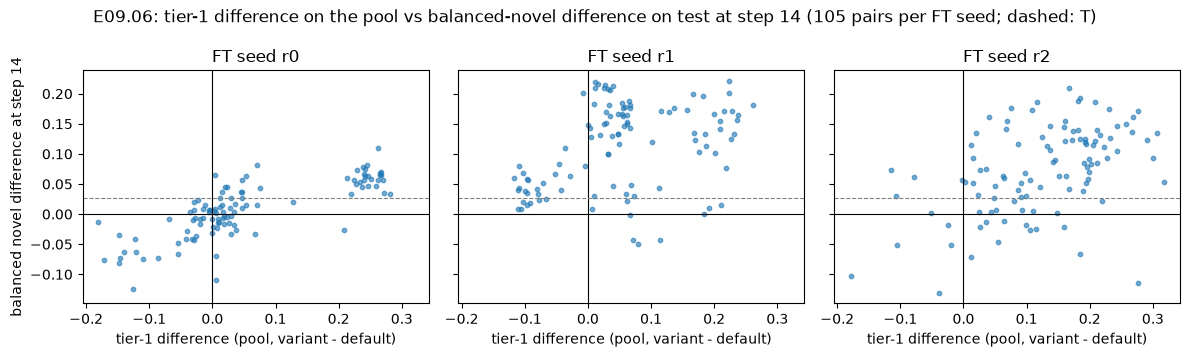

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
for a, (ft, g) in zip(ax, L.groupby("ft")):
    a.scatter(g["d_t1"], g["d_bal14"], s=10, alpha=0.6)
    a.axhline(0, lw=0.8, color="k"); a.axvline(0, lw=0.8, color="k"); a.axhline(T, lw=0.8, ls="--", color="gray")
    a.set_title(f"FT seed {ft}"); a.set_xlabel("tier-1 difference (pool, variant - default)")
ax[0].set_ylabel("balanced novel difference at step 14")
fig.suptitle("E09.06: tier-1 difference on the pool vs balanced-novel difference on test at step 14 "
             "(105 pairs per FT seed; dashed: T)")
fig.tight_layout(); plt.show()

- **Kết quả**: r0 tách hai đám: 27/105 cặp ở x ≈ 0.2–0.28, y trung vị +0.058 (nhánh mặc định mất cụm crease, trung vị `best` 0, phép gộp lấy lại, trung vị 0.906); 78 cặp quanh gốc, y trung vị −0.006 (tính tay từ `metrics.json`). r1 có nhiều cặp x < 0 mà y > 0. r2 trải y từ −0.13 tới +0.21.
- **Ý nghĩa**: ở r0, phép gộp chỉ có lợi khi k-means mặc định để mất crease, khoảng 1/4 số lần rút; các lần khác hoà hoặc thua nhẹ. Ở r1, một phần lợi xuất hiện dù tầng 1 không tăng, khớp phần tăng ở khâu đặt tên (3.1). [SUY LUẬN] Lợi của `09a` + `09b` là lợi "cứu crease" cộng với lợi ở khâu đặt tên trên test, không phải một lợi đều trên mọi lần rút.

## 4. Lớp cũ mất ở đâu

### 4.1 Hiệu giữa hai nhánh
Trên GC10 t1, lớp cũ chỉ mất do khe mới cướp ảnh (`14-eval` §2), và `old08` giống nhau ở hai nhánh. Giả thuyết của E09.06: nhánh `var` dừng lượt S muộn hơn nên khe mới cướp thêm ảnh cũ.

**Cách làm:** theo FT seed, Spearman giữa hiệu bước dừng và hiệu số ảnh test cũ đúng; hệ số góc (ảnh cũ trên 100 bước) sau khi trừ trung bình từng ảnh chụp; R² của hồi quy tuyến tính trên hiệu bước dừng và hiệu số ảnh được giữ. `pred_from_stop` = hệ số góc × hiệu bước dừng trung bình. Đây là tương quan, không phải phản thực tế.

In [11]:
res = []
for ft, g in L.groupby("ft"):
    w = within(g, ["d_old14", "d_stop_S", "d_kept"])
    A = np.column_stack([w["d_stop_S"], w["d_kept"], np.ones(len(w))])
    coef, *_ = np.linalg.lstsq(A, w["d_old14"], rcond=None)
    r2 = 1 - ((w["d_old14"] - A @ coef) ** 2).sum() / (w["d_old14"] ** 2).sum()
    res.append(dict(ft=ft, d_old14=g.d_old14.mean(), d_stop_S=g.d_stop_S.mean(), d_kept=g.d_kept.mean(),
                    rho_stop=stats.spearmanr(g.d_stop_S, g.d_old14)[0], rho_kept=stats.spearmanr(g.d_kept, g.d_old14)[0],
                    img_per_100_steps=100 * np.polyfit(w["d_stop_S"], w["d_old14"], 1)[0], r2_stop_kept=r2))
r4 = pd.DataFrame(res).set_index("ft")
r4["pred_from_stop"] = r4["img_per_100_steps"] / 100 * r4["d_stop_S"]
print(r4.round(3).to_string())

    d_old14  d_stop_S  d_kept  rho_stop  rho_kept  img_per_100_steps  r2_stop_kept  pred_from_stop
ft                                                                                                
r0   -0.333    16.200   0.819    -0.692    -0.322             -2.825         0.550          -0.458
r1   -1.333    44.714   5.990    -0.835     0.446             -3.844         0.683          -1.719
r2   -2.162    52.629   5.314    -0.121     0.217             -2.009         0.220          -1.057


- **Kết quả**: nhánh `09a` + `09b` giữ ít ảnh test cũ hơn: −0.33 / −1.33 / −2.16 ảnh (r0 / r1 / r2), dừng lượt S muộn hơn 16 / 45 / 53 bước. Spearman giữa hai hiệu: −0.69 / −0.84 / −0.12. Hệ số góc trong từng ảnh chụp: −2.8 / −3.8 / −2.0 ảnh cũ trên 100 bước. Nếu chỉ do bước dừng, mức mất dự đoán là −0.46 / −1.72 / −1.06 ảnh. R² của hồi quy trên hiệu bước dừng và hiệu số ảnh giữ: 0.55 / 0.68 / 0.22.
- **Ý nghĩa**: ở r0 và r1, bước dừng muộn giải thích hết phần lớp cũ mất. Ở r2 nó chỉ giải thích khoảng một nửa (−1.06 trên −2.16), và tương quan ở mức cặp yếu (−0.12): phần còn lại đến từ chính phân hoạch, ví dụ cụm nào cướp ảnh cũ. Đây là tương quan, chưa phải phản thực tế.

### 4.2 Mức tuyệt đối: mỗi phân hoạch một điểm
Mỗi phân hoạch khác nhau chỉ chạy bước 10–14 một lần, nên gộp hai nhánh lại và bỏ dòng trùng. Nếu bước dừng là cơ chế, quan hệ "dừng muộn hơn, ít ảnh cũ đúng hơn" phải thấy ở cả hai nhánh, không chỉ ở hiệu.

In [12]:
P = pd.concat([L[["ft", "snap", "batch", f"{a}_part", f"{a}_old14", f"{a}_stop_S", f"{a}_kept", f"{a}_bal14"]]
               .set_axis(["ft", "snap", "batch", "part", "old14", "stop_S", "kept", "bal14"], axis=1).assign(arm=a)
               for a in ("def", "var")]).drop_duplicates(["snap", "batch", "part"])
print(len(P), "distinct partitions"); print(P.groupby(["ft", "arm"]).size().unstack().to_string())
res = []
for ft, g in P.groupby("ft"):
    w = within(g, ["old14", "stop_S", "bal14"])
    res.append(dict(ft=ft, rho_old_stop=stats.spearmanr(w.stop_S, w.old14)[0],
                    img_per_100_steps=100 * np.polyfit(w.stop_S, w.old14, 1)[0],
                    rho_bal_stop=stats.spearmanr(w.stop_S, w.bal14)[0],
                    stop_min=int(g.stop_S.min()), stop_max=int(g.stop_S.max()), n=len(g)))
print(pd.DataFrame(res).round(3).to_string(index=False))
for arm, g in P.groupby("arm"):
    print(arm, "stop_S by FT seed:", g.groupby("ft")["stop_S"].mean().round(1).to_dict(),
          "| old14:", g.groupby("ft")["old14"].mean().round(2).to_dict())

613 distinct partitions
arm  def  var
ft           
r0   101  105
r1   103  105
r2    94  105
ft  rho_old_stop  img_per_100_steps  rho_bal_stop  stop_min  stop_max   n
r0        -0.698             -2.512         0.749       525       637 206
r1        -0.869             -3.559         0.544       468       617 208
r2        -0.682             -3.346         0.637       470       596 199
def stop_S by FT seed: {'r0': 589.0, 'r1': 521.8, 'r2': 495.3} | old14: {'r0': 195.76, 'r1': 199.05, 'r2': 194.41}
var stop_S by FT seed: {'r0': 605.4, 'r1': 566.5, 'r2': 548.7} | old14: {'r0': 195.44, 'r1': 197.71, 'r2': 192.23}


- **Kết quả**: 613 phân hoạch khác nhau (nhánh mặc định 101 / 103 / 94, nhánh `09a` + `09b` 105 / 105 / 105). Trong từng ảnh chụp, dừng muộn hơn đi cùng ít ảnh cũ đúng hơn (Spearman −0.70 / −0.87 / −0.68; −2.5 / −3.6 / −3.3 ảnh trên 100 bước), nhưng cũng đi cùng balanced novel cao hơn (Spearman +0.75 / +0.54 / +0.64). Bước dừng trung bình: mặc định 589 / 522 / 495, `09a` + `09b` 605 / 567 / 549. Số ảnh cũ đúng trung bình: mặc định 195.8 / 199.1 / 194.4, `09a` + `09b` 195.4 / 197.7 / 192.2.
- **Ý nghĩa**: quan hệ bước dừng – ảnh cũ có ở cả hai nhánh và ở cả ba FT seed, kể cả r2. Cùng một biến vừa làm lớp mới tốt lên vừa làm lớp cũ xấu đi: bước dừng là một trục đánh đổi cũ/mới. [SUY LUẬN] Bước dừng đi theo độ tản của cụm (`13-gauss-s`, Spearman +0.90), nên chiều nhân quả chưa rõ: phân hoạch tốt hơn → cụm tản hơn → dừng muộn hơn → khe mới vừa phủ đúng lớp mới hơn vừa cướp thêm ảnh cũ.

### 4.3 Hình: ảnh test cũ đúng theo bước dừng
Mỗi điểm là một phân hoạch khác nhau (613 điểm); tròn: nhánh mặc định, chéo: nhánh `09a` + `09b`. Nếu ở cùng một bước dừng hai nhánh giữ cùng số ảnh cũ, thì phần mất của lớp cũ chủ yếu đi qua bước dừng.

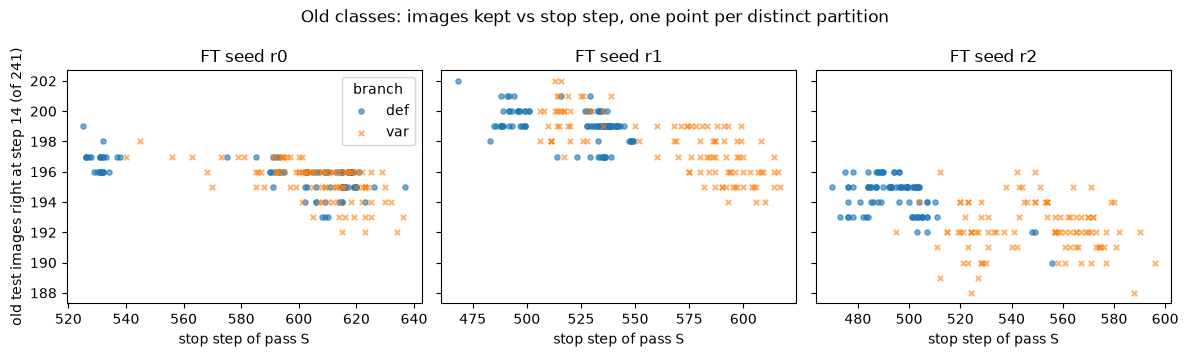

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for a, (ft, g) in zip(ax, P.groupby("ft")):
    for arm, mk in (("def", "o"), ("var", "x")):
        h = g[g.arm == arm]
        a.scatter(h["stop_S"], h["old14"], s=14, marker=mk, alpha=0.6, label=arm)
    a.set_title(f"FT seed {ft}"); a.set_xlabel("stop step of pass S")
ax[0].set_ylabel(f"old test images right at step 14 (of {N_OLD_TEST})"); ax[0].legend(title="branch")
fig.suptitle("Old classes: images kept vs stop step, one point per distinct partition")
fig.tight_layout(); plt.show()

- **Kết quả**: điểm của cả hai nhánh nằm trên cùng một dải dốc xuống ở r0 và r1. Ở các bước dừng mà hai nhánh chồng nhau (r0 590–620, r1 510–545), số ảnh cũ đúng của hai nhánh gần như bằng nhau. Ở r2, hai nhánh gần như không chồng nhau: mặc định dừng ở 470–510, `09a` + `09b` ở 510–595.
- **Ý nghĩa**: ở r0, r1, ở cùng một bước dừng, phép gộp không làm lớp cũ mất thêm. Lớp cũ mất vì nhánh `09a` + `09b` dừng muộn hơn. Ở r2 không tách được hai nguồn từ hình này, vì hai nhánh không có vùng bước dừng chung. Muốn tách thì cần phản thực tế: chạy lượt S của các phân hoạch `09a` + `09b` mà dừng ở bước của nhánh mặc định.

## 5. Vết gộp của rolled_pit và crease

### 5.1 Chạy lại K' = 20 và phép gộp trên 315 lần rút
Với mỗi ảnh chụp và mỗi lần rút k = 0…20, đặt RNG như `score.tier2_e0906`, chạy `v09a_overcluster` rồi `v09b_merge` (luật `bf`), và ghi lại từng bước gộp. Không chạy SVI. Nhãn pool chỉ dùng để chấm.

Cổng kiểm: mỗi lần rút phải trùng `metrics.json` của E09.06 ở inertia K' = 20, độ thuần gộp, và `owned`, `best` của 5 lớp mới ở hai nhánh `k20`, `bf`. Sai thì dừng.

**Cụm tiêu điểm** của lớp c: cụm con mà c sở hữu và chứa nhiều ảnh c nhất. Với nó, ghi: bước bị gộp lần đầu, lớp chủ và cỡ của nhóm đối tác, log BF của bước đó, log BF lớn nhất trong các cặp không chứa nó ở cùng thời điểm (`next_best_other`), và số nhóm do silk làm chủ lúc đó.

In [14]:
import contextlib, hashlib, io, pickle, time
from replay import load, snapshots, _fresh, _run_dir
from variants import v09a_overcluster, v09b_merge
from score import score09, _purity_0906

def merge_trace(view, yp, names, n_old, prior, focus=("rolled", "crease")):
    """One draw (global RNG already set): K' = 20 sub-clusters (09a), bf merge (09b), and the trace of the merge.
    Returns (tier-1 scores of k20 and bf, merge purity, sub_inertia, step rows, focus rows). yp: scoring only."""
    with contextlib.redirect_stdout(io.StringIO()):
        sub = v09a_overcluster(view, k=20)
        s2 = {**view, **sub}
        mer = v09b_merge(s2, "bf", prior)
    sid, steps = np.asarray(sub["sub_ids"]).astype(int), mer["merge_steps"]
    cost = merge_costs(s2, sid, prior)["bf"]                       # same rule, for the runner-up pairs
    tab = np.zeros((len(names), 20), dtype=int)
    np.add.at(tab, (yp, sid), 1)                                   # class x sub-cluster
    cnt = lambda g: tab[:, list(g)].sum(1)                         # class counts of a group of sub-clusters
    own = lambda g: names[int(cnt(g).argmax())]                    # plurality class, ties to the lower id (score09)
    foc = {}
    for c in focus:
        ci = names.index(c)
        owned = [j for j in range(20) if tab[:, j].sum() > 0 and tab[:, j].argmax() == ci]
        j = max(owned, key=lambda q: tab[ci, q]) if owned else int(tab[ci].argmax())
        foc[c] = dict(sub=j, owned20=len(owned), n_sub=int(tab[:, j].sum()), n_c_sub=int(tab[ci, j]), n_c=int(tab[ci].sum()))
    groups, srows, done = [(i,) for i in range(20)], [], set()
    for t, (ga, gb, c_) in enumerate(steps, 1):
        sizes = sorted(int(cnt(g).sum()) for g in groups)
        na, nb = int(cnt(ga).sum()), int(cnt(gb).sum())
        srows.append(dict(step=t, groups_before=len(groups), log_bf=-c_, n_a=na, n_b=nb, owner_a=own(ga), owner_b=own(gb),
                          small_rank=sizes.index(min(na, nb)) + 1, silk_groups=sum(own(g) == "silk" for g in groups)))
        for c in focus:
            j = foc[c]["sub"]
            if c in done or (j not in ga and j not in gb):
                continue
            mine, other = (ga, gb) if j in ga else (gb, ga)
            rest = [g for g in groups if g != mine]
            alt = max(-cost(*sorted((p, q))) for i, p in enumerate(rest) for q in rest[i + 1:]) if len(rest) > 1 else np.nan
            foc[c].update(step=t, groups_before=len(groups), log_bf=-c_, partner_owner=own(other),
                          partner_n=int(cnt(other).sum()), partner_n_c=int(cnt(other)[names.index(c)]),
                          mine_n=int(cnt(mine).sum()), next_best_other=alt,
                          silk_groups=sum(own(g) == "silk" for g in groups))
            done.add(c)
        groups = [g for g in groups if g not in (ga, gb)] + [tuple(sorted(ga + gb))]
    for c in focus:
        g = next(g for g in groups if foc[c]["sub"] in g)
        foc[c].update(final_owner=own(g), final_n=int(cnt(g).sum()), final_n_c=int(cnt(g)[names.index(c)]),
                      survived=int(c not in done))
    t1 = {arm: score09(yp, ids, names, n_old=n_old) for arm, ids in (("k20", sid), ("bf", np.asarray(mer["ids"])))}
    return t1, _purity_0906(yp, sid, steps), sub["sub_inertia"], srows, [dict(cls=c, **v) for c, v in foc.items()]

NAMES = [c.split("_")[0] for c in split["classes"]]
KEY = hashlib.sha256(b"".join((ROOT / "lab" / f).read_bytes() for f in ("variants.py", "niw.py", "score.py"))
                     + inspect.getsource(merge_trace).encode()).hexdigest()[:12]
S_rows, F_rows, n_ok = [], [], 0
for r in range(3):
    for N in range(5):
        tag = f"gc10_v2_ft_r{r}_s{N}"
        cache = _run_dir(tag) / "landscape" / f"b13_trace_{KEY}.pkl"
        if cache.exists():
            s_, f_ = pickle.loads(cache.read_bytes())
            src = "cache"
        else:
            t0 = time.time()
            with contextlib.redirect_stdout(io.StringIO()):
                st = load(tag, "08", check=False)
            blobs = snapshots(tag)
            _fresh(blobs, "09")
            a = st["args"]
            yp = np.asarray(st["true_pool_y"]).astype(int)                      # scoring only
            view = {key: v for key, v in st.items() if not key.startswith("true_")}
            prior = merge_prior(view)
            assert prior["off"] == RAW[(r, N, 0)]["off"], (tag, prior["off"])
            s_, f_ = [], []
            for k in range(21):
                m = RAW[(r, N, k)]
                state = blobs["09"]["rng_in"] if k == 0 else np.random.RandomState(906000 + 1000 * r + 100 * N + k).get_state()
                np.random.set_state(state)
                t1, pur, J20, srows, frows = merge_trace(view, yp, NAMES, a.base, prior)
                gate = abs(J20 - m[f"d{k}_J20"]) <= 1e-6 * m[f"d{k}_J20"] and abs(pur - m[f"d{k}_purity"]) < 1e-12 \
                    and abs(t1["bf"]["bal_acc_hungarian"] - m[f"d{k}_t1_bf_bal"]) < 1e-12 \
                    and all(abs(t1[arm][f"{q}_{c}"] - m[f"d{k}_t1_{arm}_{q}_{c}"]) < 1e-12
                            for arm in ("k20", "bf") for c in NOV for q in ("owned", "best"))
                assert gate, f"{tag} draw {k}: the trace does not reproduce E09.06"
                tagc = dict(ft=f"r{r}", seed=N, draw=k, snap=f"r{r}_s{N}")
                s_ += [dict(tagc, **x) for x in srows]
                f_ += [dict(tagc, **x) for x in frows]
            cache.parent.mkdir(exist_ok=True)
            cache.write_bytes(pickle.dumps((s_, f_)))
            src = f"{time.time() - t0:.0f} s"
        n_ok += len(f_) // 2
        S_rows += s_; F_rows += f_
        print(tag, src, "| draws reproduced:", len(f_) // 2, flush=True)
S, F = pd.DataFrame(S_rows), pd.DataFrame(F_rows)
print("gate:", n_ok, "/ 315 draws reproduce E09.06 | step rows", len(S), "| focus rows", len(F), "| cache key", KEY)

gc10_v2_ft_r0_s0 cache | draws reproduced: 21
gc10_v2_ft_r0_s1 cache | draws reproduced: 21
gc10_v2_ft_r0_s2 cache | draws reproduced: 21
gc10_v2_ft_r0_s3 cache | draws reproduced: 21
gc10_v2_ft_r0_s4 cache | draws reproduced: 21
gc10_v2_ft_r1_s0 cache | draws reproduced: 21
gc10_v2_ft_r1_s1 cache | draws reproduced: 21
gc10_v2_ft_r1_s2 cache | draws reproduced: 21
gc10_v2_ft_r1_s3 cache | draws reproduced: 21
gc10_v2_ft_r1_s4 cache | draws reproduced: 21
gc10_v2_ft_r2_s0 cache | draws reproduced: 21
gc10_v2_ft_r2_s1 cache | draws reproduced: 21
gc10_v2_ft_r2_s2 cache | draws reproduced: 21
gc10_v2_ft_r2_s3 cache | draws reproduced: 21
gc10_v2_ft_r2_s4 cache | draws reproduced: 21
gate: 315 / 315 draws reproduce E09.06 | step rows 4725 | focus rows 630 | cache key ba44deed8236


- **Kết quả**: 15 ảnh chụp, khoảng 25 s mỗi ảnh chụp; cổng kiểm đạt 315/315 lần rút (inertia K' = 20, độ thuần gộp, balanced tầng 1 sau gộp, `owned` và `best` của 5 lớp mới ở `k20` và `bf` trùng `metrics.json` của E09.06). 4725 dòng bước gộp (315 × 15), 630 dòng cụm tiêu điểm (315 × 2). Cache khoá `ba44deed8236`.
- **Ý nghĩa**: vết gộp dựng lại đúng phép gộp đã chạy trong E09.06, nên mục 5.2–5.4 đọc được như một mô tả của chính thí nghiệm đó.

### 5.2 Cụm tiêu điểm bị gộp khi nào, với ai
Chỉ xét các lần rút mà lớp có cụm riêng ở K' = 20 (cụm tiêu điểm do lớp sở hữu và chứa ít nhất nửa số ảnh của lớp). `margin` = log BF của bước gộp trừ `next_best_other`: dương nghĩa là cặp chứa cụm tiêu điểm thắng mọi cặp khác ở thời điểm đó.

In [15]:
F["share20"] = F["n_c_sub"] / F["n_c"]
F["had"] = (F["owned20"] >= 1) & (F["share20"] >= 0.5)
F["kept_own"] = (F["final_owner"] == F["cls"]) & (F["final_n_c"] / F["n_c"] >= 0.5)
F["margin"] = F["log_bf"] - F["next_best_other"]
for c in ("rolled", "crease"):
    g = F[F.cls == c]
    print(f"\n== {c}: own sub-cluster at K' = 20 in {int(g.had.sum())}/{len(g)} draws; by FT seed", g.groupby("ft")["had"].sum().to_dict())
    h = g[g.had]
    print("   sub-cluster size (median) n_sub", h.n_sub.median(), "| images of the class in it", h.n_c_sub.median(),
          "| purity", round((h.n_c_sub / h.n_sub).median(), 3))
    print("   still the class's own cluster after the merge:", h.groupby("ft")["kept_own"].sum().to_dict(),
          "| never merged (survived as a single sub-cluster):", int(h.survived.sum()))
    mg = h[h.survived == 0]
    print("   first merge, step (1-15):", mg.groupby("ft")["step"].describe()[["count", "25%", "50%", "75%"]].round(1).to_dict("index"))
    print("   partner owner at the first merge:"); print(pd.crosstab(mg["ft"], mg["partner_owner"]).to_string())
    print("   partner holds images of the class:", int((mg.partner_n_c > 0).sum()), "/", len(mg),
          "| median partner size", mg.partner_n.median(), "| median partner images of the class", mg.partner_n_c.median())
    print("   log BF of that step (median)", round(mg.log_bf.median(), 1), "| next best pair without it", round(mg.next_best_other.median(), 1),
          "| margin median", round(mg.margin.median(), 1), "| silk-owned groups at that time (median)", mg.silk_groups.median())
    print("   final owner of the cluster holding it:"); print(pd.crosstab(h["ft"], h["final_owner"]).to_string())


== rolled: own sub-cluster at K' = 20 in 203/315 draws; by FT seed {'r0': 71, 'r1': 86, 'r2': 46}
   sub-cluster size (median) n_sub 25.0 | images of the class in it 12.0 | purity 0.474
   still the class's own cluster after the merge: {'r0': 1, 'r1': 2, 'r2': 0} | never merged (survived as a single sub-cluster): 0
   first merge, step (1-15): {'r0': {'count': 71.0, '25%': 10.0, '50%': 11.0, '75%': 12.5}, 'r1': {'count': 86.0, '25%': 11.0, '50%': 12.0, '75%': 12.0}, 'r2': {'count': 46.0, '25%': 8.0, '50%': 10.0, '75%': 10.8}}
   partner owner at the first merge:
partner_owner  crease  crescent  inclusion  oil  punching  silk  waist  welding
ft                                                                             
r0                 57         0          0    7         1     0      5        1
r1                 47         4         11    3        10     1     10        0
r2                 31         4          2    0         2     5      2        0
   partner holds images of the

- **Kết quả**:
  - rolled: có cụm con riêng ở K' = 20 trong 203/315 lần rút (71 / 86 / 46). Cụm con điển hình có 25 ảnh, 12 ảnh rolled (độ thuần 0.47). Cụm con này luôn bị gộp, ở bước 10–12 (trung vị 11 / 12 / 10 trên 15 bước). Đối tác lúc gộp: nhóm do crease làm chủ ở 135/203 lần (57 / 47 / 31). log BF của bước đó có trung vị −85.3, cặp tốt nhất không chứa nó −122.6 (hơn 28.9 nat). Lúc gộp, silk còn làm chủ 3 nhóm. Chủ cuối của nhóm chứa nó: crease 132, waist 48, inclusion 19, rolled 3.
  - crease: có cụm con riêng trong 187/315 lần (81 / 28 / 78), cụm con 25 ảnh với 17 ảnh crease (độ thuần 0.73), bị gộp ở bước 10–11. Đối tác: rolled 58, waist 47, punching_hole 45 (lớp cũ), crease 20. Còn làm chủ sau gộp ở 115/187 lần; khi mất, nhóm về tay waist (52) hoặc inclusion (18).
- **Ý nghĩa**: rolled không mất vì bị gộp sớm. Nó bị gộp muộn, gần như luôn vào nhóm crease, và vì crease có nhiều ảnh hơn (32 so với 17 trên pool) nên crease làm chủ nhóm chung. log BF của bước gộp này âm: Bayes factor nói hai nhóm không nên gộp, nhưng ở thời điểm đó mọi cặp khác còn âm hơn, và K = 5 buộc phải gộp tiếp. Trong lúc đó silk vẫn giữ 3 nhóm. crease còn bị gộp với nhóm của lớp cũ punching_hole ở 45 lần rút.

### 5.3 Thứ tự gộp nói chung
Trên mọi bước gộp của 315 lần rút: bước càng muộn thì nhóm nhỏ hơn trong cặp lớn hay nhỏ (`small_rank` = hạng cỡ của nó trong các nhóm hiện có, 1 là nhỏ nhất); log BF theo bước; cặp lớp chủ nào được gộp, và ở bước nào.

In [16]:
S["min_n"] = S[["n_a", "n_b"]].min(axis=1)
S["pair"] = [" + ".join(sorted(p)) for p in zip(S.owner_a, S.owner_b)]
S["same_owner"] = S.owner_a == S.owner_b
print("Spearman(step, size of the smaller side):", {ft: round(stats.spearmanr(g.step, g.min_n)[0], 3) for ft, g in S.groupby("ft")})
print(S.groupby("step")[["log_bf", "min_n", "small_rank", "silk_groups", "same_owner"]].median().round(2).T.to_string())
print("\nshare of steps joining two groups with the same owner, by step:")
print(S.groupby(["ft", "step"])["same_owner"].mean().unstack().round(2).to_string())
top = S.groupby("pair").agg(n=("step", "size"), median_step=("step", "median"), median_log_bf=("log_bf", "median"),
                            median_min_n=("min_n", "median")).sort_values("n", ascending=False)
print("\nowner pairs (all steps):"); print(top.head(20).round(1).to_string())
last = S[S.step == 15]
print("\nlast merge (6 -> 5 groups), owner pairs:"); print(last["pair"].value_counts().head(8).to_string())

Spearman(step, size of the smaller side): {'r0': np.float64(-0.235), 'r1': np.float64(-0.103), 'r2': np.float64(0.261)}
step            1       2       3       4       5     6      7      8      9      10     11      12      13      14      15
log_bf       361.3  303.46  203.03  143.14  119.65  95.7  68.94  33.96 -10.25 -42.53 -73.71 -140.84 -232.76 -364.19 -579.42
min_n         49.0   51.00   52.00   35.00   24.00  20.0  24.00  30.00  23.00  20.00  25.00   30.00   41.00   45.00   53.00
small_rank    15.0   15.00   15.00   10.00    6.00   4.0   5.00   4.00   3.00   2.00   2.00    2.00    2.00    2.00    1.00
silk_groups    8.0    7.00    7.00    6.00    5.00   5.0   4.00   4.00   4.00   3.00   3.00    3.00    3.00    2.00    2.00
same_owner     1.0    1.00    1.00    1.00    1.00   1.0   1.00   0.00   0.00   0.00   0.00    0.00    0.00    0.00    0.00

share of steps joining two groups with the same owner, by step:
step    1     2     3     4     5     6     7     8     9     10    11 

- **Kết quả**: log BF của cặp được chọn giảm đều theo bước, từ +361 (bước 1) xuống −579 (bước 15), đổi dấu giữa bước 8 (+34) và bước 9 (−10). Tỷ lệ bước gộp hai nhóm cùng chủ: gần 1 ở bước 1–7 (trung vị), dưới 0.5 từ bước 8 trở đi. Spearman giữa bước và cỡ nhóm nhỏ hơn trong cặp yếu (−0.24 / −0.10 / +0.26). Cặp chủ hay gặp nhất: silk + silk 1547 lần (trung vị bước 4, log BF +196); inclusion + silk 863 lần (bước 8, +57); waist + waist 637 lần (bước 6, +102); inclusion + inclusion 441 lần (bước 13, −207). Bước cuối (6 → 5 nhóm) thường gộp inclusion + inclusion (84), crease + punching (58), crease + waist (40).
- **Ý nghĩa**: các bước có log BF dương gần như trùng với các bước gộp cùng chủ. [SUY LUẬN] Dấu của log BF tách được bước gộp đúng khỏi bước gộp sai, nên log BF = 0 là điểm dừng tự nhiên, ở khoảng 20 − 8 = 12 nhóm (tính tay). Cỡ nhóm không quyết định thứ tự gộp (Spearman yếu). Dự đoán rút từ ví dụ đồ chơi 2.2 (cụm con nhỏ bị gộp muộn) đúng hướng. Hai điều trái mong đợi:
  - inclusion bị gộp vào silk sớm và với log BF dương, tức Bayes factor coi một phần inclusion là cùng phân phối với silk;
  - các nhóm inclusion lại tách nhau tới bước cuối. [SUY LUẬN] Khớp `05a-camera`: camera giải thích 0.35 phương sai trong inclusion và 0.43 trong silk.

### 5.4 Hình: log BF theo bước, và bước gộp của cụm tiêu điểm
Trái: trung vị log BF của cặp được chọn ở mỗi bước, theo FT seed; đường log BF = 0 chia bước gộp được bằng chứng ủng hộ và bước gộp bị ép. Phải: bước mà cụm con riêng của rolled và crease bị gộp lần đầu, trên các lần rút có cụm con riêng.

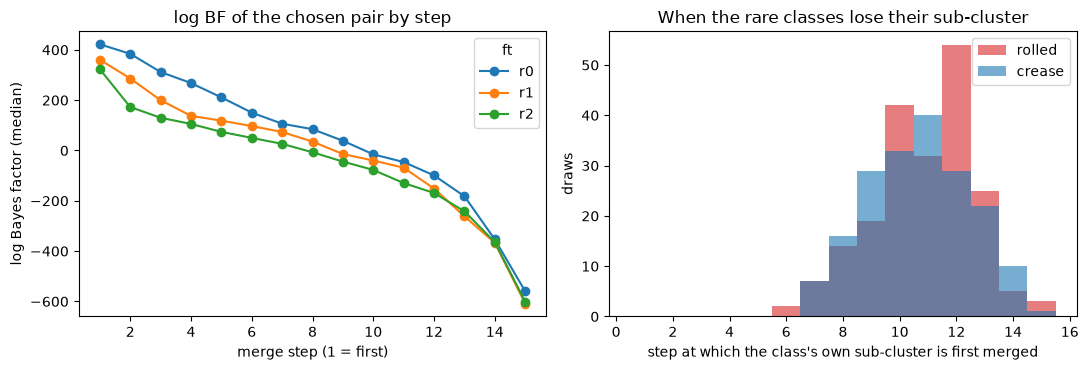

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
med = S.groupby(["ft", "step"])["log_bf"].median().unstack(0)
med.plot(ax=ax[0], marker="o"); ax[0].set_xlabel("merge step (1 = first)"); ax[0].set_ylabel("log Bayes factor (median)")
ax[0].set_title("log BF of the chosen pair by step")
for c, col in (("rolled", "C3"), ("crease", "C0")):
    h = F[(F.cls == c) & F.had & (F.survived == 0)]
    ax[1].hist(h["step"], bins=np.arange(0.5, 16.5), alpha=0.6, label=c, color=col)
ax[1].set_xlabel("step at which the class's own sub-cluster is first merged"); ax[1].set_ylabel("draws"); ax[1].legend()
ax[1].set_title("When the rare classes lose their sub-cluster")
fig.tight_layout(); plt.show()

- **Kết quả**: log BF đổi dấu ở khoảng bước 9–10 với r0 và bước 8 với r1, r2. Cụm con của rolled và crease bị gộp trong khoảng bước 6–15, dồn ở bước 10–12, tức là sau điểm đổi dấu.
- **Ý nghĩa**: lớp hiếm mất cụm ở phần gộp bị ép bởi K = 5, không ở phần gộp có bằng chứng ủng hộ.

## Summary (EN)

- The tier-1 gain of `09a` + `09b` survives naming but is mostly lost in steps 11–14: the variant-minus-default difference is 0.052 / 0.126 / 0.120 at column 10 and 0.008 / 0.112 / 0.072 at column 14 (r0 / r1 / r2; §3.1), and steps 11–14 cost the variant more than the default in all three FT seeds (0.114 / 0.113 / 0.092 vs 0.070 / 0.099 / 0.045).
- At the FT-seed level the gain is not established: Delta = 0.064, 95% CI [−0.067, 0.195], t = 2.11 with 2 df (§1.3); 65% (r1) and 89% (r2) of Delta_r comes from rolled_pit and crease, classes with 6 and 11 test images, and one rolled test image is worth 0.033 > T (§1.3, §3.2).
- The extra loss on old classes goes with the later stop of pass S: at equal stop steps both branches keep the same number of old test images in r0 and r1; in r2 the stop step explains about half (−1.06 of −2.16 images; §4.1, §4.3). Within snapshots a later stop means fewer old images right (−2.5 to −3.6 per 100 steps) and higher balanced novel (Spearman +0.54 to +0.75; §4.2) [inference: the stop step is an old/new trade-off axis].
- rolled_pit loses its sub-cluster late (merge step 10–12 of 15), mostly into the crease group (135/203 draws), at a negative log Bayes factor forced by K = 5, while silk still owns 3 groups (§5.2).
- The sign of the log Bayes factor separates same-owner merges (steps 1–7, log BF > 0) from cross-class merges (step 8 onwards; §5.3) [inference: log BF = 0 is a natural stopping point at about 12 groups].